# A/B Test Analysis: Pricing Page

This notebook follows the supplied report. It cleans the experiment and country files, then performs: (1) Welch independent-samples t-test, (2) chi-square test of independence, (3) one-way ANOVA across countries, and (4) one-way ANOVA across six country/strategy groups. The significance level is 0.05.

In Colab, upload both `ab_data.csv` and `countries.csv` when prompted. Python file names must be quoted strings in `pd.read_csv`, for example `pd.read_csv("countries.csv")`.

## 1. Upload and read the two CSV files

In [6]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

# Place both CSV files in the Colab working directory (/content),
# or change these paths to the folder where your files are stored.
df = pd.read_csv("countries.csv")
countries_df = df.copy()
ab_df = pd.read_csv("ab_data.csv")

print("A/B data shape:", ab_df.shape)
print("Countries data shape:", countries_df.shape)
display(ab_df.head())
display(countries_df.head())


A/B data shape: (294478, 5)
Countries data shape: (290584, 2)


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


,user_id,country
0,834778,UK
1,928468,US
2,822059,UK
3,711597,UK
4,710616,UK


## 2. Clean and merge

In [7]:
# Normalize text fields and validate the columns needed for the report.
required_ab = {"user_id", "timestamp", "group", "landing_page", "converted"}
required_country = {"user_id", "country"}
if not required_ab.issubset(ab_df.columns):
    raise ValueError(f"ab_data.csv needs {sorted(required_ab)}. Found: {ab_df.columns.tolist()}")
if not required_country.issubset(countries_df.columns):
    raise ValueError(f"countries.csv needs {sorted(required_country)}. Found: {countries_df.columns.tolist()}")

for col in ["group", "landing_page"]:
    ab_df[col] = ab_df[col].astype("string").str.strip().str.lower()
# Accommodate either spaced labels or underscore labels.
ab_df["landing_page"] = ab_df["landing_page"].replace({"old page": "old_page", "new page": "new_page"})
ab_df["converted"] = pd.to_numeric(ab_df["converted"], errors="coerce")
ab_df["timestamp"] = pd.to_datetime(ab_df["timestamp"], errors="coerce")
countries_df["country"] = countries_df["country"].astype("string").str.strip().str.upper()

# Remove rows with missing required experiment values or non-binary outcomes.
valid_values = ab_df[["user_id", "group", "landing_page", "converted"]].notna().all(axis=1) & ab_df["converted"].isin([0, 1])
missing_or_invalid_removed = int((~valid_values).sum())
ab_df = ab_df.loc[valid_values].copy()
ab_df["converted"] = ab_df["converted"].astype(int)

# Keep only rows where assignment and page agree with the experiment design.
valid_pair = ((ab_df["group"] == "control") & (ab_df["landing_page"] == "old_page")) |              ((ab_df["group"] == "treatment") & (ab_df["landing_page"] == "new_page"))
mismatches_removed = int((~valid_pair).sum())
clean = ab_df.loc[valid_pair].copy()

# Keep the first recorded visit per user. Sort by timestamp when possible.
clean = clean.sort_values("timestamp", na_position="last", kind="stable")
duplicate_users_removed = int(clean.duplicated(subset="user_id").sum())
clean = clean.drop_duplicates(subset="user_id", keep="first")

# Keep one country mapping per user, then merge to the cleaned experiment.
countries_df = countries_df.dropna(subset=["user_id", "country"]).drop_duplicates(subset="user_id", keep="first")
data = clean.merge(countries_df[["user_id", "country"]], on="user_id", how="inner", validate="one_to_one")

print(f"Invalid/missing experiment rows removed: {missing_or_invalid_removed:,}")
print(f"Group/page mismatches removed: {mismatches_removed:,}")
print(f"Duplicate user records removed: {duplicate_users_removed:,}")
print(f"Cleaned experiment rows: {len(clean):,}")
print(f"Rows after country merge: {len(data):,}")
print("Group counts:", data["group"].value_counts().to_dict())
print("Country counts:", data["country"].value_counts().to_dict())
display(data.head())

Invalid/missing experiment rows removed: 0
Group/page mismatches removed: 3,893
Duplicate user records removed: 1
Cleaned experiment rows: 290,584
Rows after country merge: 290,584
Group counts: {'treatment': 145310, 'control': 145274}
Country counts: {'US': 203619, 'UK': 72466, 'CA': 14499}


,user_id,timestamp,group,landing_page,converted,country
0,922696,2017-01-02 13:42:05.378582,treatment,new_page,0,US
1,781507,2017-01-02 13:42:15.234051,control,old_page,0,UK
2,737319,2017-01-02 13:42:21.786186,control,old_page,0,US
3,818377,2017-01-02 13:42:26.640581,treatment,new_page,0,US
4,725857,2017-01-02 13:42:27.851110,treatment,new_page,0,US


## 3. Descriptive conversion rates

,users,conversions,conversion_rate_pct
group,,,
control,145274,17489,12.039%
treatment,145310,17264,11.881%


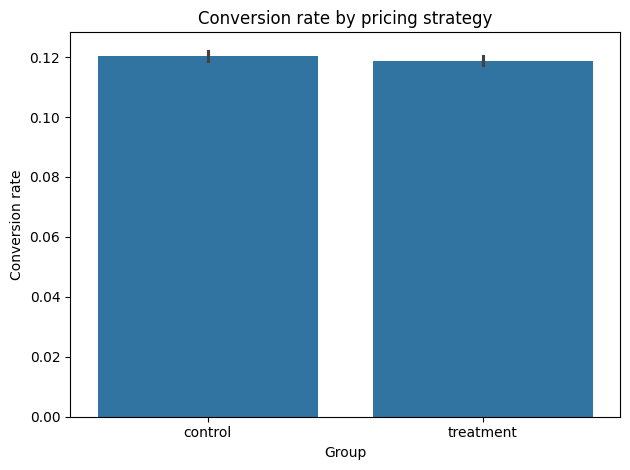

In [8]:
summary = data.groupby("group", observed=True).agg(
    users=("converted", "size"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)
summary["conversion_rate_pct"] = 100 * summary["conversion_rate"]
display(summary[["users", "conversions", "conversion_rate_pct"]].style.format({"conversion_rate_pct": "{:.3f}%"}))

sns.barplot(data=data, x="group", y="converted", order=["control", "treatment"], errorbar=("ci", 95))
plt.title("Conversion rate by pricing strategy")
plt.xlabel("Group")
plt.ylabel("Conversion rate")
plt.tight_layout()
plt.show()

## 4. Welch independent-samples t-test: control vs treatment

In [9]:
# H0: mean conversion is equal in control and treatment.
# H1: mean conversion differs between control and treatment.
control = data.loc[data["group"] == "control", "converted"].astype(float)
treatment = data.loc[data["group"] == "treatment", "converted"].astype(float)
if control.empty or treatment.empty:
    raise ValueError("Both control and treatment groups must have observations.")

test = stats.ttest_ind(treatment, control, equal_var=False, alternative="two-sided")
difference = treatment.mean() - control.mean()
se = np.sqrt(treatment.var(ddof=1) / len(treatment) + control.var(ddof=1) / len(control))
df_welch = (treatment.var(ddof=1) / len(treatment) + control.var(ddof=1) / len(control))**2 / (
    (treatment.var(ddof=1) / len(treatment))**2 / (len(treatment)-1) +
    (control.var(ddof=1) / len(control))**2 / (len(control)-1)
)
t_critical = stats.t.ppf(0.975, df_welch)
ci_low, ci_high = difference - t_critical*se, difference + t_critical*se
pooled_sd = np.sqrt(((len(treatment)-1)*treatment.var(ddof=1) + (len(control)-1)*control.var(ddof=1)) /
                    (len(treatment)+len(control)-2))
cohens_d = difference / pooled_sd

print(f"Control: n={len(control):,}, conversion={control.mean():.4%}")
print(f"Treatment: n={len(treatment):,}, conversion={treatment.mean():.4%}")
print(f"Difference (treatment - control): {difference*100:.3f} percentage points")
print(f"95% CI: [{ci_low*100:.3f}, {ci_high*100:.3f}] percentage points")
print(f"Welch t={test.statistic:.4f}, df={df_welch:.1f}, p={test.pvalue:.6f}")
print(f"Cohen's d={cohens_d:.5f}")
print("Decision at alpha=0.05:", "Reject H0" if test.pvalue < 0.05 else "Fail to reject H0")

Control: n=145,274, conversion=12.0386%
Treatment: n=145,310, conversion=11.8808%
Difference (treatment - control): -0.158 percentage points
95% CI: [-0.394, 0.078] percentage points
Welch t=-1.3109, df=290571.7, p=0.189885
Cohen's d=-0.00486
Decision at alpha=0.05: Fail to reject H0


## 5. Chi-square test of independence

In [10]:
# H0: group assignment and conversion are independent.
# H1: group assignment and conversion are associated.
contingency = pd.crosstab(data["group"], data["converted"]).reindex(
    index=["control", "treatment"], columns=[0, 1], fill_value=0
)
chi2, chi_p, chi_df, expected = chi2_contingency(contingency, correction=True)
print("Contingency table (columns 0=not converted, 1=converted):")
display(contingency.rename(columns={0: "not_converted", 1: "converted"}))
print(f"Chi-square={chi2:.4f}, df={chi_df}, p={chi_p:.6f}")
print("Decision at alpha=0.05:", "Reject H0" if chi_p < 0.05 else "Fail to reject H0")

Contingency table (columns 0=not converted, 1=converted):


converted,not_converted,converted
group,,
control,127785,17489
treatment,128046,17264


Chi-square=1.7036, df=1, p=0.191822
Decision at alpha=0.05: Fail to reject H0


## 6. One-way ANOVA across countries

In [11]:
# H0: all country mean conversion rates are equal.
country_summary = data.groupby("country", observed=True).agg(
    users=("converted", "size"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
).sort_index()
country_summary["conversion_rate_pct"] = 100 * country_summary["conversion_rate"]
display(country_summary[["users", "conversions", "conversion_rate_pct"]].style.format({"conversion_rate_pct": "{:.3f}%"}))
country_samples = [g["converted"].to_numpy() for _, g in data.groupby("country", observed=True)]
country_anova = stats.f_oneway(*country_samples)
print(f"Country ANOVA: F={country_anova.statistic:.4f}, p={country_anova.pvalue:.6f}")
print("Decision at alpha=0.05:", "Reject H0" if country_anova.pvalue < 0.05 else "Fail to reject H0")

,users,conversions,conversion_rate_pct
country,,,
CA,14499,1672,11.532%
UK,72466,8739,12.059%
US,203619,24342,11.955%


Country ANOVA: F=1.6053, p=0.200834
Decision at alpha=0.05: Fail to reject H0


## 7. One-way ANOVA across six country/strategy groups

Six-group ANOVA: F=1.4664, p=0.197087
Decision at alpha=0.05: Fail to reject H0


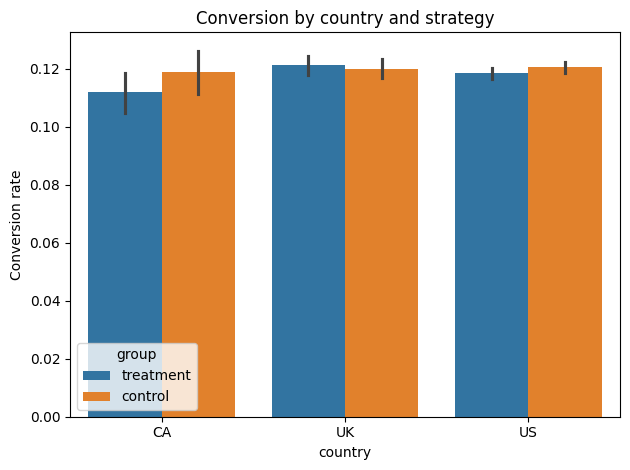

In [12]:
# H0: all country-by-strategy mean conversion rates are equal.
data["country_strategy"] = data["country"].astype(str) + " - " + data["group"].astype(str)
cell_summary = data.groupby(["country", "group"], observed=True).agg(
    users=("converted", "size"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)
cell_summary["conversion_rate_pct"] = 100 * cell_summary["conversion_rate"]
display(cell_summary[["users", "conversions", "conversion_rate_pct"]].style.format({"conversion_rate_pct": "{:.3f}%"}))
combo_samples = [g["converted"].to_numpy() for _, g in data.groupby("country_strategy", observed=True)]
combo_anova = stats.f_oneway(*combo_samples)
print(f"Six-group ANOVA: F={combo_anova.statistic:.4f}, p={combo_anova.pvalue:.6f}")
print("Decision at alpha=0.05:", "Reject H0" if combo_anova.pvalue < 0.05 else "Fail to reject H0")

sns.barplot(data=data, x="country", y="converted", hue="group", order=["CA", "UK", "US"], errorbar=("ci", 95))
plt.title("Conversion by country and strategy")
plt.ylabel("Conversion rate")
plt.tight_layout()
plt.show()

## 8. Overall conclusion

In [13]:
alpha = 0.05
print("A/B test results summary (alpha=0.05)")
print(f"Welch t-test p-value: {test.pvalue:.6f}")
print(f"Chi-square p-value: {chi_p:.6f}")
print(f"Country ANOVA p-value: {country_anova.pvalue:.6f}")
print(f"Country/strategy ANOVA p-value: {combo_anova.pvalue:.6f}")
if all(p >= alpha for p in [test.pvalue, chi_p, country_anova.pvalue, combo_anova.pvalue]):
    print("None of the tests found a statistically significant difference at alpha=0.05.")
    print("This is not proof that the strategies are identical; it means this analysis did not detect a difference.")
else:
    print("At least one test is statistically significant at alpha=0.05. Review its result and practical effect size.")

A/B test results summary (alpha=0.05)
Welch t-test p-value: 0.189885
Chi-square p-value: 0.191822
Country ANOVA p-value: 0.200834
Country/strategy ANOVA p-value: 0.197087
None of the tests found a statistically significant difference at alpha=0.05.
This is not proof that the strategies are identical; it means this analysis did not detect a difference.
